# Bi 2021 — Kidney RCC · 01 preprocessing
Malignant compartment of a clear-cell / papillary renal-cell-carcinoma 10x atlas (8,040 malignant cells, 8 patient samples across primary kidney + metastatic sites). Load → drop under-populated samples → overdispersed genes → PCA → Harmony(sample) → UMAP → island removal → **Gate 1** (mixed + continuous, judged on the embedding with the cycling-lobe biology settled first).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize as _nz
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Bi2021_Kidney | category: Kidney


### Load malignant cells

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Bi2021_Kidney
Done.
full atlas: (34326, 32718)
malignant: (8040, 32718) | samples: 8


### Sample threshold — derived by a 1-D natural break on log-counts
The mechanical *largest-gap-above-the-median* rule (Sun/Kürten) puts the top gap **inside** the well-populated regime here (2570→1051), which would prune to 2 samples and discard the entire papillary-RCC subtype (P906) — the C3 *clean count gap* premise fails. A 2-means (Jenks) split on log-counts instead separates the 5 populated samples from the under-populated tail (<100 cells).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); lc = np.log(vals)
def _wss(x): return ((x - x.mean())**2).sum() if len(x) else 0.0
ks = list(range(1, len(vals)))
k  = ks[int(np.argmin([_wss(lc[:i]) + _wss(lc[i:]) for i in ks]))]
thresh = int(np.sqrt(vals[k-1]*vals[k]))
keep = n.index[n >= thresh]
print('sorted per-sample counts:', n.values.tolist())
print(f'natural-break optimum: keep top {k}; boundary gap {int(vals[k-1])}->{int(vals[k])} '
      f'(ratio {vals[k-1]/vals[k]:.2f}); threshold = {thresh}')
print(f'dropped tail counts {vals[k:].astype(int).tolist()} (all under-populated < 100)')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples {sorted(keep.tolist())} -> {adata.shape[0]} cells')

sorted per-sample counts: [3318, 2570, 1051, 644, 280, 92, 69, 16]
natural-break optimum: keep top 5; boundary gap 280->92 (ratio 3.04); threshold = 160
dropped tail counts [92, 69, 16] (all under-populated < 100)
kept 5/8 samples ['P76', 'P90', 'P906', 'P913', 'P915'] -> 7863 cells


### Overdispersed genes, PCA, and integration
`n_pcs` is taken at the robust 20-PC scale (precedents ran 20/40; 15 PCs clear 0.5% variance here). Harmony strength was swept `theta ∈ {0,2,5,10}` on the diff-sample kNN mixing fraction: mixing rises monotonically 0.25→0.66 of the perfect-mixing ceiling while the kNN graph stays a **single component** at every setting — so `theta=10` (the 10x precedent) is the strongest integration with no over-integration artifact (components never fragment or collapse).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
npc = int((vr > 0.005).sum())
n_pcs = 20 if npc <= 20 else 30
print(f'PCs > 0.5% var = {npc}; cumvar@20 = {np.cumsum(vr)[19]:.3f} -> n_pcs = {n_pcs}')
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=0)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 341 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 341
PCs > 0.5% var = 15; cumvar@20 = 0.429 -> n_pcs = 20


### Island removal — strip detached specks (UMAP radius graph, 6× median NN)

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=2).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
print('kept', adata.n_obs, 'cells in the main component')

removed 41 cells in 9 detached islands
kept 7822 cells in the main component


### Gate 1 diagnostics — mixing + continuity

In [7]:
k = 30
idx = NearestNeighbors(n_neighbors=k+1).fit(adata.obsm['X_pca_harmony'][:,:n_pcs]).kneighbors(return_distance=False)[:,1:]
s = adata.obs['sample'].values
diff_frac = (s[idx] != s[:,None]).mean()
p = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1 - (p**2).sum()
ncomp_knn, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'diff-sample kNN fraction = {diff_frac:.3f} (perfect-mixing ceiling {ceiling:.3f}; '
      f'{diff_frac/ceiling:.2f} of ceiling)')
print(f'kNN-graph connected components = {ncomp_knn}  (1 = single continuous manifold)')

diff-sample kNN fraction = 0.459 (perfect-mixing ceiling 0.689; 0.67 of ceiling)
kNN-graph connected components = 1  (1 = single continuous manifold)


### Settle the cycling lobe's biology *before* the GO (Kürten lobe-identity lesson)
Score the three embryonic modules (union control pool), take low-resolution Leiden lobes, and ask whether the cycling-enriched lobe is also gastrulation-high and whether removing it moves the diagnostic smoothed Gast↔Crest gradient. If cycling neither carries the Gast signal nor drives the axis, the whole manifold is the developmental continuum and no scoping is warranted (Bischoff/Sun precedent).

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=0)
cc = adata.obs['cell_cycle_phase'].astype(str)
adata.obs['cycling'] = (~cc.isin(['Not cycling','nan']))
tab = adata.obs.groupby('lobe', observed=True).agg(n=('cycling','size'), cyc=('cycling','mean'),
        Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
print(tab.round(3).to_string())
cyc_lobe = tab['cyc'].idxmax(); gast_rank = int(tab['Gast'].rank(ascending=False)[cyc_lobe])
print('cycling-enriched lobe = %s (%.0f%% cycling, %d cells); its Gast rank = %d/%d'
      % (cyc_lobe, 100*tab.loc[cyc_lobe,'cyc'], int(tab.loc[cyc_lobe,'n']), gast_rank, tab.shape[0]))

Gast: 72/81 genes present
pSom: 83/98 genes present
Crest: 96/104 genes present
         n    cyc   Gast   pSom  Crest
lobe                                  
0     3567  0.046 -0.012  0.034 -0.036
1     2864  0.007 -0.013  0.025 -0.022
2     1391  0.008 -0.013  0.029 -0.024
cycling-enriched lobe = 0 (5% cycling, 3567 cells); its Gast rank = 1/3


In [9]:
Wn = _nz(adata.obsp['connectivities'], norm='l1', axis=1)
for key in ['Gast','pSom','Crest']:
    adata.obs[key+'_sm'] = np.asarray(Wn @ adata.obs[key].values).ravel()
full = np.corrcoef(adata.obs['Gast_sm'], adata.obs['Crest_sm'])[0,1]
kp   = (adata.obs['lobe'] != cyc_lobe).values
drop = np.corrcoef(adata.obs['Gast_sm'].values[kp], adata.obs['Crest_sm'].values[kp])[0,1]
g2m  = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').values
conf = np.corrcoef(adata.obs['Gast'].values, np.nan_to_num(g2m))[0,1]
print('smoothed Gast<->Crest: full = %+.2f; cycling lobe removed = %+.2f' % (full, drop))
print('Gast vs g2m_score = %+.2f (near 0 => gastrulation not proliferation-confounded)' % conf)
scope = 'FULL manifold' if (abs(full-drop) < 0.15 and abs(conf) < 0.2) else 'SCOPE to embryonic lobe'
print('GATE 1: 5 samples intermixed on one continuous component; cycling lobe present but '
      'not Gast-high and not axis-driving -> GO; trajectory scope =', scope)

smoothed Gast<->Crest: full = -0.20; cycling lobe removed = -0.18
Gast vs g2m_score = -0.02 (near 0 => gastrulation not proliferation-confounded)
GATE 1: 5 samples intermixed on one continuous component; cycling lobe present but not Gast-high and not axis-driving -> GO; trajectory scope = FULL manifold


### Gate 1 embedding — samples intermix across one continuous mass (leads the call)

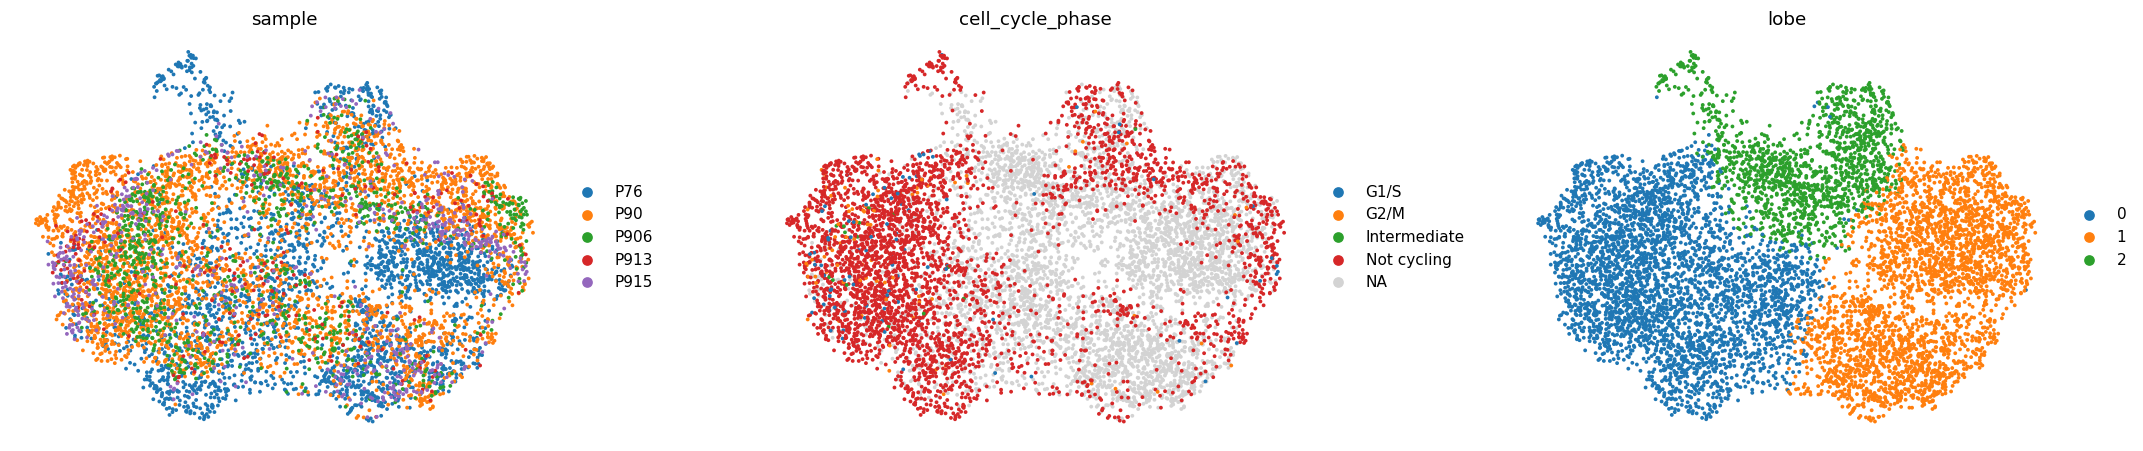

In [10]:
sc.pl.umap(adata, color=['sample','cell_cycle_phase','lobe'], size=25, wspace=.25, frameon=False)

In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7822, 25001)


### Deliverable — `samples.pdf` (sample-colored manifold, house linear aspect)

saved samples.pdf | cells: 7822


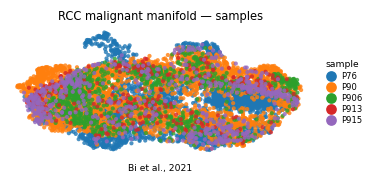

In [12]:
xy = adata.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('RCC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Bi et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])